# 02 · Classic CNN architectures: LeNet → AlexNet → VGG

**Covers (Week 3 Key Concepts, "CNN Architectures"):** LeNet (1998), AlexNet (2012), VGG (2014).
**Questions answered here:** Easy 1–9 · Medium 1–4 · Hard 2, 10.

| Year | Model | One-line contribution |
|---|---|---|
| 1998 | **LeNet-5** (Yann LeCun) | **Proof of concept**: CNNs can read handwriting (cheques, zip codes) |
| 2012 | **AlexNet** (Krizhevsky, Sutskever, Hinton) | **The breakthrough**: won ImageNet by a huge margin using ReLU, dropout and GPUs |
| 2014 | **VGG** (Visual Geometry Group, Oxford) | **Depth + simplicity**: 16–19 layers, only small 3×3 filters |
| 2015 | ResNet | made *very* deep networks trainable (notebook 03) |
| 2019 | EfficientNet | balanced, efficient scaling (notebook 03) |
| 2020 | Vision Transformer | attention instead of convolution (notebook 07) |

We'll **build and train LeNet** ourselves (it runs in seconds on a laptop CPU), then **inspect** AlexNet and VGG. Those are too big to train here, but we can build them and look inside.

In [1]:
%matplotlib inline
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

torch.manual_seed(0)
print("torch", torch.__version__)

torch 2.14.1+cu130


## 1 · Data: handwritten digits

LeNet was trained on **MNIST**: 70,000 handwritten digits, 28×28 pixels, padded to 32×32. MNIST needs a download, so we use scikit-learn's built-in **digits** dataset instead. It has the same idea (handwritten 0–9) but is smaller: 1,797 images of 8×8. We **resize them to 32×32**, LeNet's input size.

train: (1257, 1, 32, 32)  test: (540, 1, 32, 32)


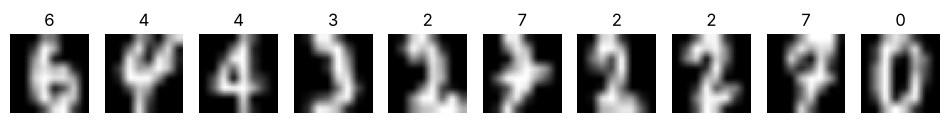

In [2]:
digits = load_digits()
X = torch.tensor(digits.images, dtype=torch.float32)[:, None] / 16.0      # (1797, 1, 8, 8), values 0..1
X = F.interpolate(X, size=(32, 32), mode="bilinear", align_corners=False)  # -> (1797, 1, 32, 32)
y = torch.tensor(digits.target)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
print("train:", tuple(Xtr.shape), " test:", tuple(Xte.shape))

fig, ax = plt.subplots(1, 10, figsize=(12, 1.6))
for i in range(10):
    ax[i].imshow(Xtr[i, 0], cmap="gray"); ax[i].set_title(int(ytr[i])); ax[i].axis("off")
plt.show()

## 2 · LeNet-5 (1998)

**Inventor:** Yann LeCun (Bell Labs). **Purpose:** digit recognition. It was used to read **bank cheques and postal codes**.
**Architecture:** **Convolution → Pooling → Convolution → Pooling → Fully Connected → Fully Connected → Output.**

```
input 32×32 ─ conv 5×5 (6 maps) ─ pool ─ conv 5×5 (16 maps) ─ pool ─ FC 120 ─ FC 84 ─ 10 classes
              "find strokes"            "combine strokes"            "decide which digit"
```

The original used tanh/sigmoid and average pooling. We use ReLU and max-pooling, the modern defaults, and compare activations later.

In [3]:
class LeNet5(nn.Module):
    def __init__(self, act=nn.ReLU):
        super().__init__()
        self.features = nn.Sequential(                # feature extraction (convolutions)
            nn.Conv2d(1, 6, kernel_size=5), act(), nn.MaxPool2d(2),
            nn.Conv2d(6, 16, kernel_size=5), act(), nn.MaxPool2d(2))
        self.classifier = nn.Sequential(              # decision making (fully connected)
            nn.Flatten(),
            nn.Linear(16 * 5 * 5, 120), act(),
            nn.Linear(120, 84), act(),
            nn.Linear(84, 10))

    def forward(self, x):
        return self.classifier(self.features(x))

model = LeNet5()

# Trace one image through the network and print the shape after every layer
x = Xtr[:1]
print(f"{'layer':<34} output shape")
print(f"{'input':<34} {tuple(x.shape)}")
for layer in list(model.features) + list(model.classifier):
    x = layer(x)
    print(f"{str(layer):<34} {tuple(x.shape)}")
print(f"\nTotal parameters: {sum(p.numel() for p in model.parameters()):,}")

layer                              output shape
input                              (1, 1, 32, 32)
Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1)) (1, 6, 28, 28)
ReLU()                             (1, 6, 28, 28)
MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False) (1, 6, 14, 14)
Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1)) (1, 16, 10, 10)
ReLU()                             (1, 16, 10, 10)
MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False) (1, 16, 5, 5)
Flatten(start_dim=1, end_dim=-1)   (1, 400)
Linear(in_features=400, out_features=120, bias=True) (1, 120)
ReLU()                             (1, 120)
Linear(in_features=120, out_features=84, bias=True) (1, 84)
ReLU()                             (1, 84)
Linear(in_features=84, out_features=10, bias=True) (1, 10)

Total parameters: 61,706


Read the shapes:
- **32×32 → 28×28** after a 5×5 convolution with no padding (32 − 5 + 1 = 28, the Week-1 formula).
- **28 → 14** after 2×2 pooling, **14 → 10** after the second 5×5 conv, **10 → 5** after pooling.
- 16 maps × 5 × 5 = **400 numbers** are flattened and sent to the fully connected layers.

The whole of LeNet has only about **62 thousand** parameters. AlexNet has about 61 *million* (see below).

### Train it

In [4]:
def train(model, epochs=15, lr=1e-3, batch=64, augment=None, verbose=True):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), batch):
            idx = perm[i:i + batch]
            xb = Xtr[idx] if augment is None else augment(Xtr[idx], seed=epoch * 10_000 + i)
            loss = F.cross_entropy(model(xb), ytr[idx])
            opt.zero_grad(); loss.backward(); opt.step()
        history.append(accuracy(model, Xte))
        if verbose and (epoch % 5 == 4 or epoch == 0):
            print(f"epoch {epoch + 1:>2}: test accuracy {history[-1]:.1%}")
    return history

def accuracy(model, X_, y_=None):
    y_ = yte if y_ is None else y_
    model.eval()
    with torch.no_grad():
        return (model(X_).argmax(1) == y_).float().mean().item()

torch.manual_seed(0)
lenet = LeNet5()
t = time.time()
hist_relu = train(lenet)
print(f"\nLeNet-5 final test accuracy: {hist_relu[-1]:.1%}  (trained in {time.time() - t:.1f} s on CPU)")

epoch  1: test accuracy 57.2%


epoch  5: test accuracy 91.7%


epoch 10: test accuracy 95.4%


epoch 15: test accuracy 95.9%

LeNet-5 final test accuracy: 95.9%  (trained in 2.9 s on CPU)


### What did LeNet learn? Look at its filters and feature maps

The first layer has **6 learned 5×5 kernels**. Applying them to a digit gives 6 **feature maps**. Each one lights up where its pattern (a stroke direction, an edge or a blob) appears.

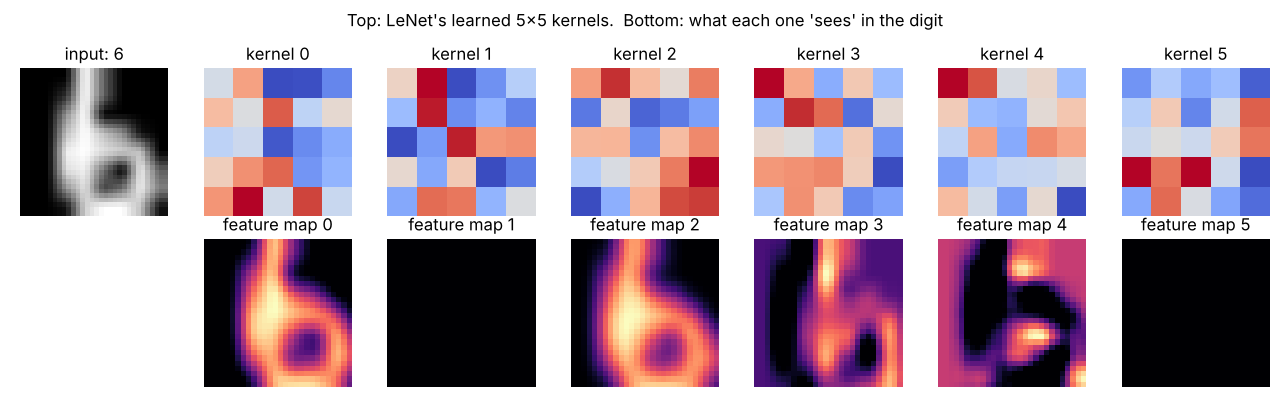

In [5]:
sample = Xte[3:4]
with torch.no_grad():
    maps = F.relu(lenet.features[0](sample))[0]           # output of first conv + ReLU

fig, ax = plt.subplots(2, 7, figsize=(13, 4))
ax[0, 0].imshow(sample[0, 0], cmap="gray"); ax[0, 0].set_title(f"input: {int(yte[3])}")
ax[1, 0].axis("off"); ax[0, 0].axis("off")
for i in range(6):
    ax[0, i + 1].imshow(lenet.features[0].weight[i, 0].detach(), cmap="coolwarm")
    ax[0, i + 1].set_title(f"kernel {i}"); ax[0, i + 1].axis("off")
    ax[1, i + 1].imshow(maps[i], cmap="magma"); ax[1, i + 1].set_title(f"feature map {i}"); ax[1, i + 1].axis("off")
plt.suptitle("Top: LeNet's learned 5x5 kernels.  Bottom: what each one 'sees' in the digit")
plt.tight_layout(); plt.show()

Different kernels respond to different parts of the stroke: some to its edges on one side, some to the whole body of the stroke. A completely black map means that kernel's pattern isn't in this digit at all (ReLU turned every negative response into 0). It may fire on other digits. **Nobody programmed these.** They're Week-1-style edge and stroke detectors that LeNet discovered by itself from the data.

### LeNet vs "traditional machine learning" (Medium Q1)

The course's exam answer: *LeNet was the **first proof** that CNNs beat traditional ML methods (like SVMs, support vector machines) on images, which inspired their use in handwriting recognition and banking.*

Let's test it honestly on our small dataset. We'll also test **shifted** digits (moved up to 4 pixels), because CNNs are supposed to be good at "find the pattern wherever it is".

In [6]:
from sklearn.svm import SVC

def shift(images, max_shift=4, seed=0):
    # move every image by a random amount (up to max_shift pixels in x and y)
    g = torch.Generator().manual_seed(seed)
    out = torch.empty_like(images)
    for i in range(len(images)):
        dx, dy = torch.randint(-max_shift, max_shift + 1, (2,), generator=g).tolist()
        out[i] = torch.roll(images[i], shifts=(dy, dx), dims=(1, 2))
    return out

Xte_shifted = shift(Xte)

svm = SVC(gamma="scale").fit(Xtr.reshape(len(Xtr), -1), ytr)      # SVM sees the raw 1,024 pixel values
svm_clean = svm.score(Xte.reshape(len(Xte), -1), yte)
svm_shift = svm.score(Xte_shifted.reshape(len(Xte), -1), yte)

# Fair comparison: give BOTH models training data with shifted copies (augmentation)
torch.manual_seed(0)
lenet_aug = LeNet5()
train(lenet_aug, epochs=25, augment=shift, verbose=False)          # sees new random shifts every epoch
X_aug = torch.cat([Xtr] + [shift(Xtr, seed=s) for s in range(1, 4)])   # SVM: original + 3 shifted copies
svm_aug = SVC(gamma="scale").fit(X_aug.reshape(len(X_aug), -1), ytr.repeat(4))

def svm_scores(m):
    return m.score(Xte.reshape(len(Xte), -1), yte), m.score(Xte_shifted.reshape(len(Xte), -1), yte)

rows = [("SVM (raw pixels)", (svm_clean, svm_shift)),
        ("LeNet-5", (accuracy(lenet, Xte), accuracy(lenet, Xte_shifted))),
        ("SVM + shifted training copies", svm_scores(svm_aug)),
        ("LeNet-5 + shifted training copies", (accuracy(lenet_aug, Xte), accuracy(lenet_aug, Xte_shifted)))]
print(f"{'model':<36}{'normal test':>12}{'shifted test':>14}")
for name, (a, b) in rows:
    print(f"{name:<36}{a:>12.1%}{b:>14.1%}")

model                                normal test  shifted test
SVM (raw pixels)                           98.9%         69.3%
LeNet-5                                    95.9%         67.2%
SVM + shifted training copies              99.4%         95.6%
LeNet-5 + shifted training copies          98.3%         93.3%


**Honest result:** on this *tiny* dataset (1,257 training images, originally 8×8 pixels) a modern SVM is **just as good or slightly better** than LeNet. Both collapse on shifted digits (about 70%) until they're trained on shifted examples (augmentation, from Week 1 Day 2), and then both recover to over 90%.

So why do we credit LeNet?
- **In 1998, on MNIST** (60,000 training images), LeNet-5 reached about **0.95% error**. That was on par with the best SVMs of the time, while being **much faster and smaller to run**, which mattered for reading millions of cheques. Boosted LeNet variants did best of all.
- **CNNs learn their own features.** The SVM only works this well because the digits are tiny, centred and clean. As images get bigger and messier (real photos, many classes), hand-made features plus SVMs fall far behind. AlexNet proved that dramatically in 2012.

> **Exam answer (Medium Q1):** LeNet showed that a CNN trained end-to-end on raw pixels could match or beat the best traditional methods (SVMs with hand-crafted features) on handwriting recognition, while learning its own features. That led to real deployments in banking (cheque reading) and postal services.

## 3 · AlexNet (2012): the breakthrough

**Event:** won the **ImageNet** competition (ILSVRC 2012: 1.2 million photos, 1,000 classes) by a huge margin.

| | Top-5 error | Top-5 accuracy |
|---|---|---|
| Best entry *before* deep learning (2011, hand-crafted features) | ≈ 26% | ≈ 74% |
| **AlexNet (2012)** | **≈ 15.3%** | **≈ 85%** |

The second-best entry in 2012 scored about 26%, so AlexNet's lead was more than 10 points. The course notes summarise this as "~70% → ~85%+". **Top-5 accuracy** means "the right answer is somewhere in the model's 5 best guesses".

**Architecture: 5 convolutional layers + 3 fully connected layers.**

In [7]:
from torchvision.models import alexnet
anet = alexnet(weights=None)          # build the architecture with random weights (no download)
print(anet)

convs = [m for m in anet.modules() if isinstance(m, nn.Conv2d)]
fcs = [m for m in anet.modules() if isinstance(m, nn.Linear)]
n_conv = sum(p.numel() for m in convs for p in m.parameters())
n_fc = sum(p.numel() for m in fcs for p in m.parameters())
print(f"\n{len(convs)} conv layers + {len(fcs)} fully connected layers")
print(f"parameters: conv {n_conv / 1e6:.1f} M   +   FC {n_fc / 1e6:.1f} M   =   {(n_conv + n_fc) / 1e6:.1f} M total")

AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=9216, out_features=4096, bias=True)
 

Notice: **about 95% of AlexNet's parameters are in the 3 fully connected layers.** That's exactly why it needed **dropout** (you can see `Dropout(p=0.5)` in the classifier above). Those huge layers would otherwise memorise the training set.

### AlexNet's three innovations

| Innovation | What it did |
|---|---|
| **ReLU activation** | much faster training than sigmoid/tanh; less vanishing gradient |
| **Dropout** | reduced overfitting in the giant FC layers |
| **GPU training** | split across 2 NVIDIA GTX 580 GPUs, it trained in about a week instead of months |

Plus heavy **data augmentation** (random crops and flips, from Day 2) and **overlapping max-pooling**.

#### ReLU vs sigmoid, measured (Easy Q5, Hard Q2)
Let's train LeNet three times, changing only the activation:

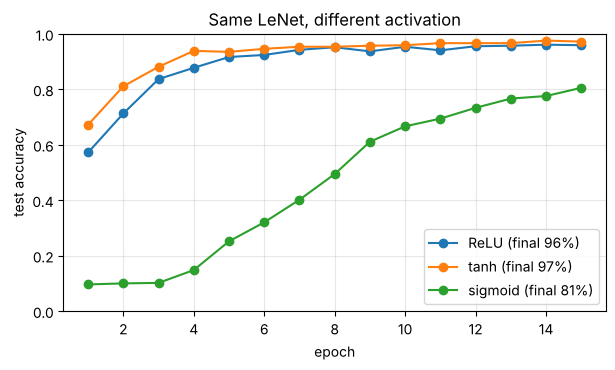

In [8]:
results = {"ReLU": hist_relu}
for name, act in [("tanh", nn.Tanh), ("sigmoid", nn.Sigmoid)]:
    torch.manual_seed(0)
    results[name] = train(LeNet5(act=act), verbose=False)

plt.figure(figsize=(7, 3.6))
for name, h in results.items():
    plt.plot(range(1, len(h) + 1), h, "o-", label=f"{name} (final {h[-1]:.0%})")
plt.xlabel("epoch"); plt.ylabel("test accuracy"); plt.ylim(0, 1)
plt.title("Same LeNet, different activation"); plt.legend(); plt.grid(alpha=0.3); plt.show()

**Sigmoid learns much more slowly.** It's stuck near 10% (random guessing) for the first epochs because its small slopes (≤ 0.25) shrink the training signal at every layer. **ReLU and tanh both learn fast here.** This network is shallow (5 weight layers) and the modern Adam optimizer helps, so tanh keeps up, even edging ahead. The gap grows with depth and with the plain SGD optimizer used in 2012. In AlexNet's paper a ReLU network reached the target error **about 6× faster** than the same network with tanh.

> **Why ReLU reduces vanishing gradients (Hard Q2):** the gradient of ReLU is exactly 1 for every positive input, so the error signal passes backwards through many layers without shrinking. Sigmoid and tanh have slopes well below 1 almost everywhere and near 0 when saturated, and multiplying many small numbers makes the gradient vanish. ReLU is also cheaper to compute (no exponentials), which made training faster.

#### Why GPUs mattered (Medium Q2)
Training a CNN is mostly **millions of independent multiply-adds** (every kernel at every position). A CPU has a few powerful cores. A GPU has **thousands of small cores** that do these in parallel. Let's time one AlexNet forward pass on this machine's CPU:

In [9]:
batch = torch.randn(16, 3, 224, 224)       # 16 photos of 224x224
anet.eval()
with torch.no_grad():
    t = time.time(); anet(batch); cpu_time = time.time() - t
print(f"AlexNet forward pass, 16 images, CPU: {cpu_time:.2f} s")
print(f"One pass over ImageNet (1.2 M images) would take about {cpu_time / 16 * 1.2e6 / 3600:.1f} hours on this CPU - "
      "and training needs a backward pass too (about 2-3x more work), repeated ~90 times.")
print("GPU available here:", torch.cuda.is_available(), "- on a GPU the same work is typically 10-50x faster.")

AlexNet forward pass, 16 images, CPU: 0.08 s
One pass over ImageNet (1.2 M images) would take about 1.8 hours on this CPU - and training needs a backward pass too (about 2-3x more work), repeated ~90 times.
GPU available here: False - on a GPU the same work is typically 10-50x faster.


## 4 · VGG (2014): deep and simple

**VGG** (Visual Geometry Group, Oxford). **Architecture:** very deep, **16–19 layers** (VGG-16 and VGG-19).
**Design choice:** use **only small 3×3 filters**, stacked. No 11×11 or 5×5 like AlexNet.
**Contribution:** showed that **depth improves accuracy**. Its uniform, simple design made it a standard **baseline** in research.

In [10]:
from torchvision.models import vgg16, vgg19

for name, fn in [("VGG-16", vgg16), ("VGG-19", vgg19)]:
    net = fn(weights=None)
    n_conv = sum(isinstance(m, nn.Conv2d) for m in net.modules())
    n_fc = sum(isinstance(m, nn.Linear) for m in net.modules())
    kernel_sizes = {m.kernel_size for m in net.modules() if isinstance(m, nn.Conv2d)}
    print(f"{name}: {n_conv} conv + {n_fc} FC = {n_conv + n_fc} weight layers, "
          f"kernel sizes used: {kernel_sizes}, parameters: {sum(p.numel() for p in net.parameters()) / 1e6:.0f} M")
    del net

VGG-16: 13 conv + 3 FC = 16 weight layers, kernel sizes used: {(3, 3)}, parameters: 138 M


VGG-19: 16 conv + 3 FC = 19 weight layers, kernel sizes used: {(3, 3)}, parameters: 144 M


### Why stack small 3×3 filters? (Medium Q4)

1. **Same view, fewer weights.** Two 3×3 layers in a row "see" a 5×5 area of the input, and three of them see 7×7. That's the same **receptive field** as one big 7×7 filter, with fewer parameters.
2. **More non-linearity.** Three layers means three ReLUs instead of one, so the network can learn more complex patterns.

Let's **measure** the receptive field. We ask: "which input pixels can change the centre output pixel?" Backpropagation answers exactly that.

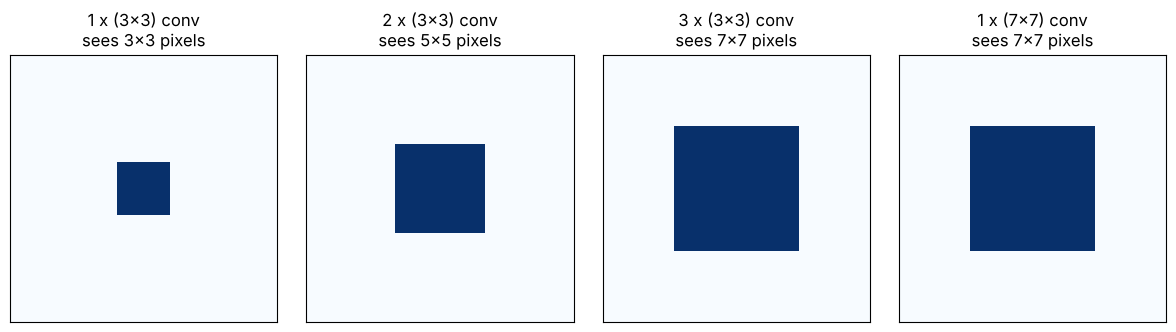

Parameters for C=64 channels in and out:
  one 7x7 layer      : 7*7*C*C   = 200,704
  three 3x3 layers   : 3*3*3*C*C = 110,592   (55% of the 7x7 cost, with 3 ReLUs instead of 1)


In [11]:
def receptive_field(layers, size=15):
    x = torch.zeros(1, 1, size, size, requires_grad=True)
    out = layers(x)
    out[0, 0, out.shape[2] // 2, out.shape[3] // 2].backward()     # nudge the centre output
    return (x.grad[0, 0] != 0).numpy()                              # which inputs affected it?

def stack(k, n):
    torch.manual_seed(0)
    layers = []
    for _ in range(n):
        conv = nn.Conv2d(1, 1, k, padding=k // 2, bias=False)
        nn.init.constant_(conv.weight, 1.0)
        layers.append(conv)
    return nn.Sequential(*layers)

fig, ax = plt.subplots(1, 4, figsize=(12, 3.2))
for a, (k, n) in zip(ax, [(3, 1), (3, 2), (3, 3), (7, 1)]):
    rf = receptive_field(stack(k, n))
    a.imshow(rf, cmap="Blues"); a.set_xticks([]); a.set_yticks([])
    a.set_title(f"{n} x ({k}x{k}) conv\nsees {rf.sum(1).max()}x{rf.sum(0).max()} pixels")
plt.tight_layout(); plt.show()

C = 64   # channels in and out
print(f"Parameters for C={C} channels in and out:")
print(f"  one 7x7 layer      : 7*7*C*C   = {49 * C * C:,}")
print(f"  three 3x3 layers   : 3*3*3*C*C = {27 * C * C:,}   ({27 / 49:.0%} of the 7x7 cost, with 3 ReLUs instead of 1)")

Three stacked 3×3 layers see the same 7×7 window as one 7×7 layer, with **45% fewer parameters** and **three** non-linearities. That's VGG's core idea, and almost every later CNN (ResNet included) uses 3×3 convolutions.

**VGG's downside:** about 138 million parameters (mostly in the FC layers again). It's slow and memory-hungry. ResNet and EfficientNet (next notebook) fix this.

---
## Key takeaways (from the Key Concepts sheet)
- **LeNet:** proof of concept (conv → pool → FC). Digits, cheques.
- **AlexNet:** breakthrough in scale and performance. ReLU + dropout + GPUs, 5 conv + 3 FC, won ImageNet 2012 by about 10 points.
- **VGG:** depth and simplicity as design principles. 16–19 layers, all 3×3 filters, a research baseline.
- Together they form the **timeline of CNN evolution**, and that trend toward deeper and better-designed networks led to ResNet, EfficientNet and Vision Transformers (Hard Q10, answered in `practice/question_bank_answers.md`).

## ✅ Check yourself
1. Who invented LeNet, what was it for, and what dataset was it trained on? *(Yann LeCun; handwritten digit recognition for cheques and postal codes; MNIST)*
2. LeNet's layer pattern? *(conv → pool → conv → pool → FC → FC → output)*
3. AlexNet's biggest achievement and three innovations? *(won ImageNet 2012 by a huge margin; ReLU, dropout, GPU training)*
4. How many layers does AlexNet have? *(5 conv + 3 FC)*
5. How many layers does VGG have, and what filter size did it standardise? *(16–19; 3×3)*
6. What receptive field do three stacked 3×3 convs have? *(7×7)*
7. Why is most of AlexNet's/VGG's parameter count in the FC layers? *(every FC neuron connects to every input value; conv kernels are tiny and shared)*